# Micheal：TW 侧化与解码

仅分析 **TW contra−ipsi × Late / Early / Late−Early**。FW 蓝色、BW 橙色；黑点为平均 r ± SEM。图中显示 p、BF₁₀，表中保留 r 和 SEM。组检验使用被试 Fisher z 的双侧 t 检验，p 未校正。

仅保存图片；统计结果在下方显示。偏相关图同时导出到 Micheal 的 `no-bl` 绘图目录。


In [1]:
# Locate the project independently of the machine and Jupyter launch directory.
import os as _path_os
import sys as _path_sys
from pathlib import Path as _ProjectPath
_path_start = _ProjectPath(__file__).resolve().parent if '__file__' in globals() else _ProjectPath.cwd()
_path_roots = ([_ProjectPath(_path_os.environ['TRAVELLING_WAVES_ROOT']).expanduser()]
               if _path_os.environ.get('TRAVELLING_WAVES_ROOT') else [])
_path_roots += [_path_start, *_path_start.parents]
_path_root = next((p for p in _path_roots if (p / 'project_locations.py').is_file()), None)
if _path_root is None:
    _path_roots = [p for mount, pattern in [('/Volumes', '*/travelling_waves'),
                    ('/media', '*/*/travelling_waves'), ('/mnt', '*/travelling_waves')]
                   for p in _ProjectPath(mount).glob(pattern)
                   if (p / 'project_locations.py').is_file()]
    if len(_path_roots) != 1:
        raise FileNotFoundError('Cannot uniquely locate travelling_waves. Set TRAVELLING_WAVES_ROOT to its directory.')
    _path_root = _path_roots[0]
_path_sys.path.insert(0, str(_path_root))
from project_locations import project_path, font_path

%matplotlib inline
from pathlib import Path
import sys, importlib
from shutil import copyfile
import pandas as pd
from IPython.display import display
# Start Jupyter within the project; locate the shared path settings.
CODE_DIR = Path(project_path('tw/decoding_gpu'))
sys.path.insert(0, str(CODE_DIR))
BASE = CODE_DIR / "micheal/behavior_corr"
sys.path.insert(0, str(BASE / 'fixed_window'))
import micheal_tw_fixed_decoding_partial_corr as analysis
importlib.reload(analysis)
from functions.corratlation_funcs import correlation_statistics, tw_decoding_corr_plot_funcs as corr_plots
importlib.reload(correlation_statistics)
importlib.reload(corr_plots)

# Select the decoding version here; save figures only, and display statistics inline.
DECODING_DIR = analysis.DEC
TW_DIR = analysis.TW
TW_WINDOW = (1.8, 3.8)
FREQUENCY_BAND = (8, 12)
SUBJECTS = list(range(1, 20))
SESSIONS = [1, 2]
TARGETS = ('late', 'early', 'late_minus_early')
out = Path(DECODING_DIR) / 'tw_correlation'
FIG_DIR = out / 'figures'
PUBLICATION_FIG_DIR = Path(project_path('tw/result/figs/micheal/no-bl'))
out.mkdir(parents=True, exist_ok=True)
print('Output:', out)

def show_group_statistics(table):
    """Print Fisher-z group r and the arithmetic mean r ± SEM used in the plot."""
    report = table.copy()
    report['mean_r ± SEM'] = [f'{mean:.6f} ± {sem:.6f}'
                              for mean, sem in zip(report.mean_r, report.sem_r)]
    columns = ['target', 'measure', 'N', 'r', 'mean_r', 'sem_r',
               'mean_r ± SEM', 't', 'df', 'p_raw', 'BF10']
    display(report[columns])

MEASURES = ('FW_contra_minus_ipsi', 'BW_contra_minus_ipsi')
PANELS = [(target, 'contra_minus_ipsi', corr_plots.DECODING_TITLES[target])
          for target in TARGETS]


Output: /media/dilay/T7/travelling_waves/tw/result/micheal_fix_decoding_new/tw_correlation


In [2]:
trials = analysis.extract(
    dec_dir=DECODING_DIR, tw_dir=TW_DIR, tw_window=TW_WINDOW,
    frequency_band=FREQUENCY_BAND, subjects=SUBJECTS, sessions=SESSIONS)
residuals = analysis.residualize(trials)
display(trials.groupby(['subject', 'session']).size().unstack())


subject 01, session 1: 760 trials
subject 01, session 2: 758 trials
subject 02, session 1: 825 trials
subject 02, session 2: 775 trials
subject 03, session 1: 654 trials
subject 03, session 2: 692 trials
subject 04, session 1: 799 trials
subject 04, session 2: 772 trials
subject 05, session 1: 785 trials
subject 05, session 2: 764 trials
subject 06, session 1: 764 trials
subject 06, session 2: 744 trials
subject 07, session 1: 761 trials
subject 07, session 2: 743 trials
subject 08, session 1: 774 trials
subject 08, session 2: 694 trials
subject 09, session 1: 733 trials
subject 09, session 2: 685 trials
subject 10, session 1: 828 trials
subject 10, session 2: 821 trials
subject 11, session 1: 772 trials
subject 11, session 2: 767 trials
subject 12, session 1: 788 trials
subject 12, session 2: 803 trials
subject 13, session 1: 825 trials
subject 13, session 2: 787 trials
subject 14, session 1: 673 trials
subject 14, session 2: 665 trials
subject 15, session 1: 774 trials
subject 15, se

session,1,2
subject,,
1,760,758
2,825,775
3,654,692
4,799,772
5,785,764
6,764,744
7,761,743
8,774,694
9,733,685


## 偏相关

每个 session 控制原始 trial 顺序，分别计算偏相关；被试内等权平均 Fisher z。


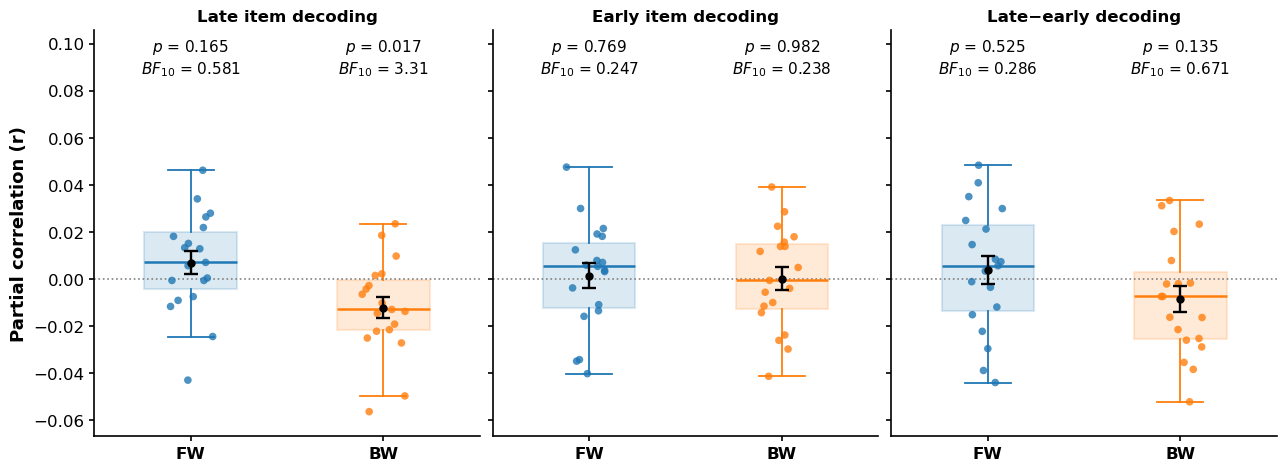

,target,measure,N,r,mean_r,sem_r,mean_r ± SEM,t,df,p_raw,BF10
0,late,BW_contra_minus_ipsi,19,-0.012082,-0.012077,0.004608,-0.012077 ± 0.004608,-2.620610,18,0.017331,3.305323
1,late,FW_contra_minus_ipsi,19,0.007013,0.007011,0.004843,0.007011 ± 0.004843,1.447455,18,0.164963,0.581384
2,early,BW_contra_minus_ipsi,19,0.000113,0.000113,0.004919,0.000113 ± 0.004919,0.022880,18,0.981998,0.237580
3,early,FW_contra_minus_ipsi,19,0.001544,0.001544,0.005183,0.001544 ± 0.005183,0.297803,18,0.769263,0.247198
4,late_minus_early,BW_contra_minus_ipsi,19,-0.008623,-0.008619,0.005505,-0.008619 ± 0.005505,-1.565722,18,0.134825,0.670809
5,late_minus_early,FW_contra_minus_ipsi,19,0.003914,0.003913,0.006042,0.003913 ± 0.006042,0.647511,18,0.525475,0.286381


Saved: /media/dilay/T7/travelling_waves/tw/result/micheal_fix_decoding_new/tw_correlation/figures/cue_partial_correlation.png
Saved: /media/dilay/T7/travelling_waves/tw/result/figs/micheal/no-bl/cue_partial_correlation.png


In [3]:
subject_tables = []
for target in TARGETS:
    _, subjects, sessions = analysis.within_session_correlations(
        residuals, MEASURES, 'D_' + target)
    subjects['target'] = target
    subject_tables.append(subjects)
all_subjects = pd.concat(subject_tables, ignore_index=True)
partial_results = corr_plots.plot_correlation_boxes(all_subjects,
    panels=PANELS, out=FIG_DIR, name='cue_partial_correlation', show_r=False)
show_group_statistics(partial_results)
print('Saved:', FIG_DIR / 'cue_partial_correlation.png')

# Export only the partial-correlation figure to the shared TW figure directory.
PUBLICATION_FIG_DIR.mkdir(parents=True, exist_ok=True)
copyfile(FIG_DIR / 'cue_partial_correlation.png',
         PUBLICATION_FIG_DIR / 'cue_partial_correlation.png')
print('Saved:', PUBLICATION_FIG_DIR / 'cue_partial_correlation.png')


## 直接 Pearson 相关

相同 trials，直接计算 Pearson r，不控制 trial 顺序；同样在被试内等权平均 session Fisher z。


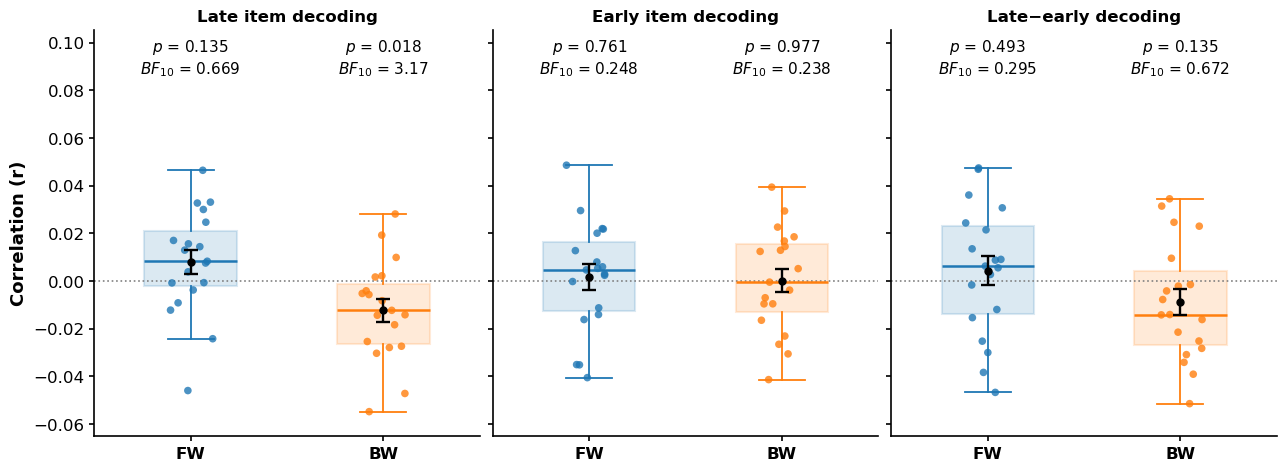

,target,measure,N,r,mean_r,sem_r,mean_r ± SEM,t,df,p_raw,BF10
0,late,BW_contra_minus_ipsi,19,-0.012354,-0.012348,0.004756,-0.012348 ± 0.004756,-2.596382,18,0.018238,3.170473
1,late,FW_contra_minus_ipsi,19,0.007864,0.007862,0.005027,0.007862 ± 0.005027,1.563589,18,0.135325,0.669029
2,early,BW_contra_minus_ipsi,19,0.000145,0.000146,0.004987,0.000146 ± 0.004987,0.029120,18,0.977089,0.237615
3,early,FW_contra_minus_ipsi,19,0.001633,0.001632,0.005287,0.001632 ± 0.005287,0.308654,18,0.761129,0.247930
4,late_minus_early,BW_contra_minus_ipsi,19,-0.008830,-0.008826,0.005634,-0.008826 ± 0.005634,-1.566551,18,0.134631,0.671503
5,late_minus_early,FW_contra_minus_ipsi,19,0.004374,0.004372,0.006251,0.004372 ± 0.006251,0.699300,18,0.493303,0.295313


Saved: /media/dilay/T7/travelling_waves/tw/result/micheal_fix_decoding_new/tw_correlation/ordinary_correlation/combined_ordinary_correlation.png


In [4]:
import numpy as np
from scipy import stats

ordinary_out = out / 'ordinary_correlation'
ordinary_out.mkdir(parents=True, exist_ok=True)
ordinary_subject_tables = []
for target in TARGETS:
    rows = []
    for subject, person in trials.groupby('subject'):
        groups = person.groupby('session')
        for session, table in groups:
            for measure in MEASURES:
                r = stats.pearsonr(table[measure], table['D_' + target]).statistic
                rows.append(dict(subject=subject, session=session, measure=measure,
                    n_trials=len(table), r=r,
                    fisher_z=np.arctanh(np.clip(r, -1+1e-12, 1-1e-12))))
    session_results = pd.DataFrame(rows)
    subjects = session_results.groupby(['subject', 'measure']).agg(
        fisher_z=('fisher_z', 'mean'), n_trials=('n_trials', 'sum')).reset_index()
    subjects['r'] = np.tanh(subjects.fisher_z)
    subjects['target'] = target
    ordinary_subject_tables.append(subjects)
ordinary_all_subjects = pd.concat(ordinary_subject_tables, ignore_index=True)
ordinary_results = corr_plots.plot_correlation_boxes(ordinary_all_subjects,
    panels=PANELS, out=ordinary_out, name='combined_ordinary_correlation',
    ylabel='Correlation (r)', show_r=False)
show_group_statistics(ordinary_results)
print('Saved:', ordinary_out / 'combined_ordinary_correlation.png')
